# DDPM (Denoising Diffusion Probabilistic Model): basic architecture

**Goal:** build the core pieces of DDPM (Ho et al., 2020) from scratch.

### The idea in one picture

```
FORWARD (fixed, no learning):   x_0 --add noise--> x_1 --> ... --> x_T  (pure noise)
REVERSE (learned):              x_T --denoise--> x_{T-1} --> ... --> x_0  (new image)
```

- **Forward process:** add a little Gaussian noise at each of `T` steps. After enough steps the image is pure `N(0, I)`.
- **Reverse process:** a network learns to undo one step. Start from random noise, denoise `T` times, get an image.
- The network does not predict the clean image. It predicts **the noise** that was added. That makes the loss a plain MSE.

## 1. Setup

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


## 2. Noise schedule

`beta_t` is how much noise step `t` adds. Linear from `1e-4` to `0.02` over `T = 1000` steps (paper values).

Useful derived terms:
- `alpha_t = 1 - beta_t`
- `alpha_bar_t = alpha_1 * alpha_2 * ... * alpha_t` (how much of the original signal survives to step `t`)

The trick: jump straight from `x_0` to any `x_t` in one shot, no loop:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \quad \epsilon \sim N(0, I)$$

In [2]:
def linear_beta_schedule(T, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)

## 3. Timestep embedding

The network must know *which* step it is denoising: step 900 (mostly noise) needs very different work than step 10 (almost clean).
We turn the integer `t` into a vector with sinusoidal features (same idea as Transformer positional encoding), then an MLP.

In [3]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)

## 4. Noise-prediction network: a small time-conditioned U-Net

An off-the-shelf U-Net (e.g. `segmentation_models_pytorch.Unet`) has no input for `t`, so we build a small one.

- **ResBlock:** two convs + skip connection. The time embedding is projected and **added** to the feature map in the middle, so every block knows `t`.
- **U-Net:** downsample twice, a middle block, upsample twice with skip connections. Output has the same shape as the input (it is the predicted noise).

In [4]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(t_emb))[:, :, None, None]  # inject timestep
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    def __init__(self, in_ch=1, base_ch=64, time_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base_ch),
            nn.Linear(base_ch, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        c1, c2, c3 = base_ch, base_ch * 2, base_ch * 4
        self.in_conv = nn.Conv2d(in_ch, c1, 3, padding=1)

        # Encoder
        self.down1 = ResBlock(c1, c1, time_dim)
        self.pool1 = nn.Conv2d(c1, c1, 4, stride=2, padding=1)   # H -> H/2
        self.down2 = ResBlock(c1, c2, time_dim)
        self.pool2 = nn.Conv2d(c2, c2, 4, stride=2, padding=1)   # H/2 -> H/4

        # Bottleneck
        self.mid1 = ResBlock(c2, c3, time_dim)
        self.mid2 = ResBlock(c3, c2, time_dim)

        # Decoder (input channels doubled by skip concat)
        self.up2 = nn.ConvTranspose2d(c2, c2, 4, stride=2, padding=1)  # H/4 -> H/2
        self.dec2 = ResBlock(c2 + c2, c1, time_dim)
        self.up1 = nn.ConvTranspose2d(c1, c1, 4, stride=2, padding=1)  # H/2 -> H
        self.dec1 = ResBlock(c1 + c1, c1, time_dim)

        self.out = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, in_ch, 3, padding=1))

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        x = self.in_conv(x)

        s1 = self.down1(x, t_emb)
        s2 = self.down2(self.pool1(s1), t_emb)
        h = self.pool2(s2)

        h = self.mid2(self.mid1(h, t_emb), t_emb)

        h = self.dec2(torch.cat([self.up2(h), s2], dim=1), t_emb)
        h = self.dec1(torch.cat([self.up1(h), s1], dim=1), t_emb)
        return self.out(h)

## 5. The DDPM wrapper

Three jobs:

| Method | What it does |
|---|---|
| `add_noise(x0, t)` | forward process: `x_0 -> x_t` in one shot, returns `x_t` and the noise used |
| `loss(x0)` | pick random `t`, noise the image, ask the U-Net to predict the noise, MSE |
| `sample(n)` | reverse process: start at `N(0, I)`, denoise `T` steps |

One reverse step (paper, Algorithm 2):

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t)\right) + \sqrt{\beta_t}\,z, \quad z \sim N(0, I)$$

No noise `z` is added on the last step (`t = 0`).

In [5]:
class DDPM(nn.Module):
    def __init__(self, model, T=1000):
        super().__init__()
        self.model = model
        self.T = T

        betas = linear_beta_schedule(T)
        alphas = 1.0 - betas
        alpha_bars = torch.cumprod(alphas, dim=0)

        # register_buffer: moves with .to(device), saved in state_dict, not trained
        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("alpha_bars", alpha_bars)

    def add_noise(self, x0, t):
        noise = torch.randn_like(x0)
        a_bar = self.alpha_bars[t][:, None, None, None]
        xt = a_bar.sqrt() * x0 + (1 - a_bar).sqrt() * noise
        return xt, noise

    def loss(self, x0):
        t = torch.randint(0, self.T, (x0.size(0),), device=x0.device)
        xt, noise = self.add_noise(x0, t)
        return F.mse_loss(self.model(xt, t), noise)

    @torch.no_grad()
    def sample(self, n, shape):
        x = torch.randn(n, *shape, device=self.betas.device)
        for i in reversed(range(self.T)):
            t = torch.full((n,), i, device=x.device, dtype=torch.long)
            eps = self.model(x, t)
            beta, alpha, a_bar = self.betas[i], self.alphas[i], self.alpha_bars[i]
            x = (x - beta / (1 - a_bar).sqrt() * eps) / alpha.sqrt()
            if i > 0:
                x = x + beta.sqrt() * torch.randn_like(x)
        return x

    def forward(self, x0):
        return self.loss(x0)

## 6. Sanity check

Shapes only, no training. Images are expected in `[-1, 1]` (scale with `x * 2 - 1` after `ToTensor()`).
A 28x28 MNIST image works: 28 -> 14 -> 7 -> 14 -> 28.

In [6]:
unet = UNet(in_ch=1, base_ch=64)
ddpm = DDPM(unet, T=1000).to(device)
print(f"U-Net parameters: {sum(p.numel() for p in unet.parameters()) / 1e6:.2f}M")

x0 = torch.randn(8, 1, 28, 28, device=device).clamp(-1, 1)
t = torch.randint(0, ddpm.T, (8,), device=device)
xt, noise = ddpm.add_noise(x0, t)
print("x_t:", xt.shape, " predicted noise:", unet(xt, t).shape)
print("loss (untrained):", ddpm(x0).item())

# Short reverse chain just to check it runs end to end
ddpm_small = DDPM(unet, T=10).to(device)
print("sample:", ddpm_small.sample(2, (1, 28, 28)).shape)

U-Net parameters: 2.94M


x_t: torch.Size([8, 1, 28, 28])  predicted noise: torch.Size([8, 1, 28, 28])


loss (untrained): 1.0673015117645264
sample: torch.Size([2, 1, 28, 28])


## 7. MNIST data

`ToTensor()` gives `[0, 1]`. DDPM noise is `N(0, 1)`, so we scale images to `[-1, 1]`.

In [7]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x * 2 - 1)])
train_ds = datasets.MNIST("../data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST("../data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128)
print(len(train_ds), "train images,", len(test_ds), "test images")


def show(x, nrow=8, title=None, ax=None):
    """Plot a batch of [-1, 1] images as one grid."""
    from torchvision.utils import make_grid
    grid = make_grid((x.clamp(-1, 1) + 1) / 2, nrow=nrow, padding=2).cpu()
    ax = ax or plt.gca()
    ax.imshow(grid[0], cmap="gray"); ax.axis("off")
    if title: ax.set_title(title)

60000 train images, 10000 test images


## 8. Train

Fresh model. Each batch: random `t`, add noise, predict the noise, MSE. That is the whole training loop.

In [8]:
import time

torch.manual_seed(0)
model = UNet(in_ch=1, base_ch=64)
ddpm = DDPM(model, T=1000).to(device)
opt = torch.optim.Adam(ddpm.parameters(), lr=2e-4)

EPOCHS = 5
losses = []
start = time.time()
for epoch in range(EPOCHS):
    ddpm.train()
    total = 0.0
    for x, _ in train_loader:
        loss = ddpm(x.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
        total += loss.item() * x.size(0)
    print(f"epoch {epoch + 1}/{EPOCHS}  train loss {total / len(train_ds):.4f}  ({time.time() - start:.0f}s)")

torch.save(ddpm.state_dict(), "../outputs/ddpm_mnist.pt")

epoch 1/5  train loss 0.0666  (493s)


epoch 2/5  train loss 0.0324  (924s)


epoch 3/5  train loss 0.0285  (1258s)


epoch 4/5  train loss 0.0269  (1591s)


epoch 5/5  train loss 0.0258  (1954s)


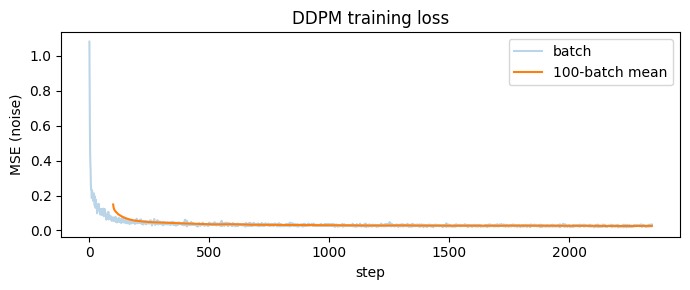

In [9]:
plt.figure(figsize=(7, 3))
plt.plot(losses, alpha=0.3, label="batch")
k = 100
plt.plot(range(k - 1, len(losses)), torch.tensor(losses).unfold(0, k, 1).mean(1), label=f"{k}-batch mean")
plt.xlabel("step"); plt.ylabel("MSE (noise)"); plt.title("DDPM training loss"); plt.legend()
plt.tight_layout(); plt.savefig("../outputs/ddpm_training.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Test

Two checks on images the model never saw:

1. **Test loss:** same noise-prediction MSE on the test set. Close to train loss means no overfitting.
2. **One-shot denoise:** noise a test digit to step `t`, then use the predicted noise to guess the clean image in one step:
$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t, t)}{\sqrt{\bar\alpha_t}}$$
Small `t` should come back almost perfect. Large `t` gets blurry, which is why sampling uses many small steps.

test loss: 0.0276


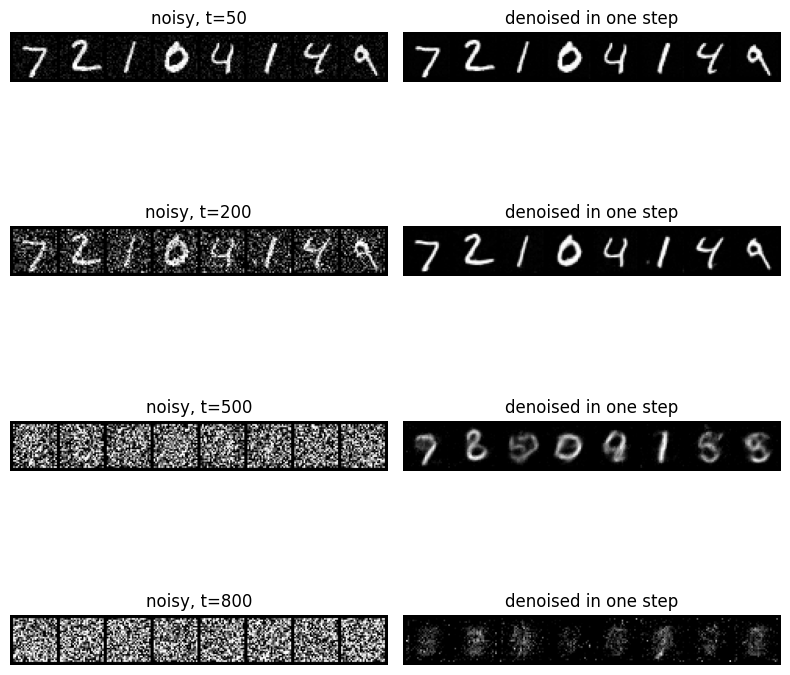

In [10]:
ddpm.eval()
torch.manual_seed(0)
with torch.no_grad():
    test_loss = sum(ddpm(x.to(device)).item() * x.size(0) for x, _ in test_loader) / len(test_ds)
print(f"test loss: {test_loss:.4f}")

x0 = next(iter(test_loader))[0][:8].to(device)
steps = [50, 200, 500, 800]
fig, axes = plt.subplots(len(steps), 2, figsize=(8, 2.2 * len(steps)))
with torch.no_grad():
    for row, s in enumerate(steps):
        t = torch.full((x0.size(0),), s, device=device, dtype=torch.long)
        xt, _ = ddpm.add_noise(x0, t)
        a_bar = ddpm.alpha_bars[s]
        x0_hat = (xt - (1 - a_bar).sqrt() * model(xt, t)) / a_bar.sqrt()
        show(xt, nrow=8, title=f"noisy, t={s}", ax=axes[row, 0])
        show(x0_hat, nrow=8, title=f"denoised in one step", ax=axes[row, 1])
plt.tight_layout(); plt.savefig("../outputs/ddpm_denoise_test.png", dpi=120, bbox_inches="tight"); plt.show()

## 10. Generate new digits

Start from pure noise and run all 1000 reverse steps. No test image involved: these digits are new.

sampled 64 images in 3s


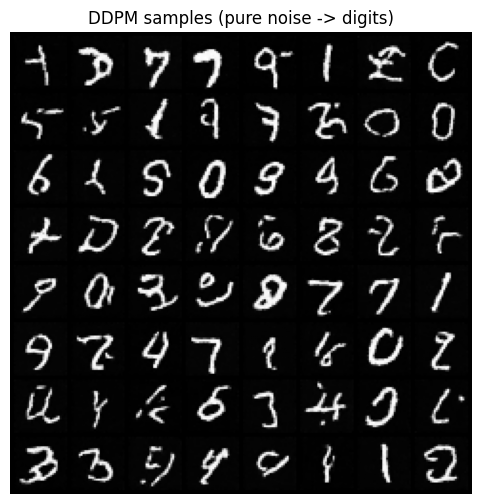

In [11]:
torch.manual_seed(42)
start = time.time()
samples = ddpm.sample(64, (1, 28, 28))
print(f"sampled 64 images in {time.time() - start:.0f}s")

plt.figure(figsize=(6, 6))
show(samples, nrow=8, title="DDPM samples (pure noise -> digits)")
plt.savefig("../outputs/ddpm_samples.png", dpi=120, bbox_inches="tight"); plt.show()

### Watch one image appear

Same reverse loop as `sample`, but keep a snapshot every 100 steps.

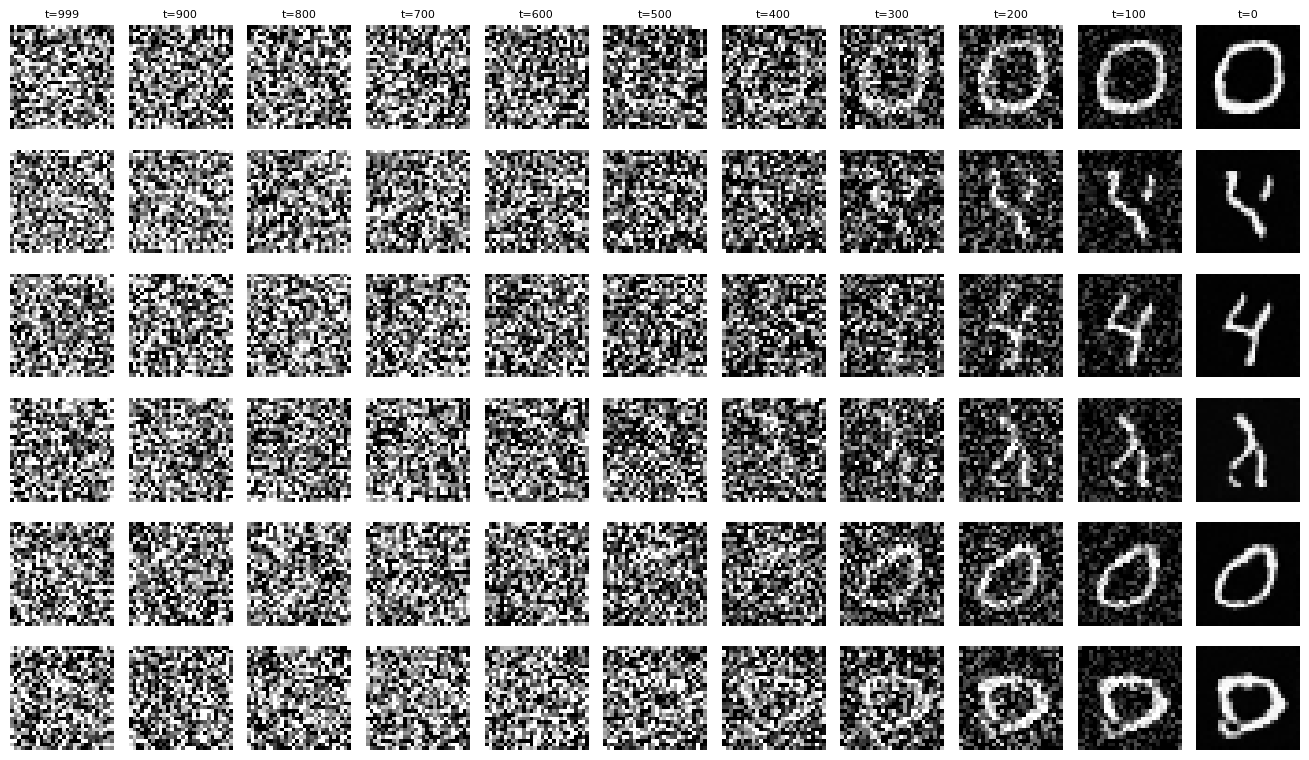

In [12]:
torch.manual_seed(7)
n = 6
x = torch.randn(n, 1, 28, 28, device=device)
snaps = {}
with torch.no_grad():
    for i in reversed(range(ddpm.T)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        eps = model(x, t)
        beta, alpha, a_bar = ddpm.betas[i], ddpm.alphas[i], ddpm.alpha_bars[i]
        x = (x - beta / (1 - a_bar).sqrt() * eps) / alpha.sqrt()
        if i > 0:
            x = x + beta.sqrt() * torch.randn_like(x)
        if i % 100 == 0 or i == ddpm.T - 1:
            snaps[i] = x.clone()

keys = sorted(snaps, reverse=True)
fig, axes = plt.subplots(n, len(keys), figsize=(1.2 * len(keys), 1.3 * n))
for c, k in enumerate(keys):
    for r in range(n):
        axes[r, c].imshow(snaps[k][r, 0].clamp(-1, 1).cpu(), cmap="gray"); axes[r, c].axis("off")
    axes[0, c].set_title(f"t={k}", fontsize=8)
plt.tight_layout(); plt.savefig("../outputs/ddpm_reverse_process.png", dpi=120, bbox_inches="tight"); plt.show()

## Next steps

- Train longer (20+ epochs) for cleaner digits.
- Add self-attention in the bottleneck for sharper samples on bigger images.
- Swap the linear schedule for a cosine schedule (Nichol & Dhariwal, 2021).
- Use DDIM sampling to cut 1000 steps down to ~50.